# Wave Phenomena

**Seong Cho** · ACME Volume 4, Lab 10

**Lab objective:** solve the wave equation with an explicit finite difference method, watch its CFL condition and dispersive errors, and use a Crank-Nicolson method to see that the travelling wave solution of Burgers' equation is stable.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
from scipy.sparse import diags
import matplotlib.pyplot as plt
from matplotlib import animation
from mpl_toolkits.mplot3d import Axes3D
from IPython.display import HTML    # [compat]: animations are embedded as HTML

In [2]:
%matplotlib inline
# [compat]: was %matplotlib notebook, which doesn't render when executed or on GitHub
plt.rcParams['figure.dpi'] = 72    # Changed: the old inline default resolution, keeps the animations small

## The advection and wave equations

The *advection* (transport) equation $u_t + su_x = 0$, $u(x,0) = f(x)$, has the solution $u(x,t) = f(x - st)$: a travelling wave that carries the signal $f$ at constant speed $s$, to the right if $s > 0$ and to the left if $s < 0$.

Many wave phenomena, in electromagnetics, fluid dynamics and acoustics, are described by the hyperbolic *wave equation*

$$u_{tt} = s^2\Delta u. \qquad \textbf{(10.1)}$$

In one dimension, the change of variables $(\xi, \eta) = (x - st, x + st)$ turns $u_{tt} = s^2u_{xx}$ into $u_{\xi\eta} = 0$, whose general solution is $u = F(\xi) + G(\eta)$. So $u(x,t) = F(x - st) + G(x + st)$ is the sum of a signal travelling right and a signal travelling left, both with speed $|s|$. The usual initial boundary value problem is

$$u_{tt} = s^2u_{xx}, \quad 0 < x < l, \quad t > 0, \qquad u(0,t) = u(l,t) = 0, \qquad u(x,0) = f(x), \quad u_t(x,0) = g(x).$$

## Numerical solution of the wave equation

On a grid $(x_j, t_m)$, centered second differences in time and space give

$$U_j^{m+1} = -U_j^{m-1} + 2(1-\lambda^2)U_j^m + \lambda^2(U_{j+1}^m + U_{j-1}^m), \qquad \lambda = \frac{s\,\Delta t}{\Delta x},$$

or $U^{m+1} = AU^m - U^{m-1}$ with $A = \operatorname{tridiag}(\lambda^2, 2(1-\lambda^2), \lambda^2)$ acting on the interior values $U^m_1, \dots, U^m_{J-1}$ (the boundary conditions give $U^m_0 = U^m_J = 0$). The method needs two starting steps: $U_j^0 = f(x_j)$, and a Taylor expansion together with $u_{tt} = s^2 f''$ gives the second order approximation

$$U_j^1 = U_j^0 + g(x_j)\Delta t + \frac{\lambda^2}{2}\left(U_{j-1}^0 - 2U_j^0 + U_{j+1}^0\right), \qquad 1 \le j \le J-1$$

(or $s^2f''(x_j)\Delta t^2/2$ in place of the last term when $f$ is easy to differentiate). The method is conditionally stable; the CFL condition is $\lambda \le 1$.

## Problem 1: A standing wave

> **Problem 1.** Complete the function `wave_eqn()` by implementing the method given in the lab.
>
> Consider the initial boundary value problem
>
> $$\begin{aligned} u_{tt} &= u_{xx}, \\ u(0,t) &= u(1,t) = 0, \\ u(x,0) &= \sin(2\pi x), \\ u_t(x,0) &= 0. \end{aligned}$$
>
> Numerically approximate the solution $u(x,t)$ for $t \in [0,.5]$. Use $J=50$ subintervals in the $x$ dimension and $M=50$ subintervals in the $t$ dimension. Animate the results. Compare your results with the analytic solution $u(x,t) = \sin(2\pi x)\cos(2\pi t)$. This function is known as a standing wave.

In [3]:
def wave_eqn(s,f,g,a,b,t_f,J,M):
    """Computes a numerical solution for the wave equation 
    initial/boundary value problem on a line:
    
        u_tt = (s^2)u_xx, x∈[a,b], t∈[0,t_f]
        u(a,t) = u(b,t) = 0
        u(x,0) = f(x)
        u_t(x,0) = g(x)
        
    Parameters
    ----------
        s (float): wave speed
        f (function): initial amplitude
        g (function): initial velocity
        a (float): left-hand space boundary
        b (float): right-hand space boundary
        t_f (float): final time value
        J (int): number of space steps
        M (int): number of time steps
    
    Returns
    ----------
        x (ndarray of shape (J+1,)): spacial domain points
        t (ndarray of shape (M+1,)): time domain points
        U (ndarray of shape (M+1,J+1)): Approximate solution array
    """
    x = np.linspace(a, b, J+1)
    t = np.linspace(0, t_f, M+1)
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    lambda_ = s*dt/dx
    U = np.zeros((M+1, J+1))
    U[0, 1:-1] = f(x[1:-1])
    U[1, 1:-1] = \
        U[0, 1:-1] + g(x[1:-1])*dt + \
        lambda_**2/2 * (U[0, :-2] - 2*U[0, 1:-1] + U[0, 2:])
    A = diags([lambda_**2, 2*(1 - lambda_**2), lambda_**2], [-1, 0, 1], shape=(J-1, J-1))
    for i in range(2, M+1):
        U[i, 1:-1] = A@U[i-1, 1:-1] - U[i-2, 1:-1]
    return x, t, U
    

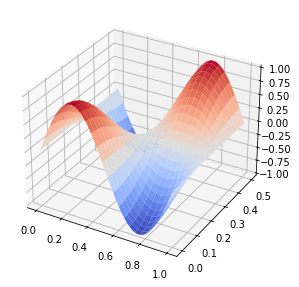

In [4]:
s, a, b, t_f, J, M = 1, 0, 1, 0.5, 50, 50
f = lambda x: np.sin(2*np.pi*x)
g = lambda x: 0*x
x, t, U = wave_eqn(s, f, g, a, b, t_f, J, M)
X, T = np.meshgrid(x, t)
fig = plt.figure()
ax = fig.add_subplot(projection='3d')    # [compat]: gca() no longer takes a projection
ax.plot_surface(X, T, U, cmap="coolwarm")
plt.show()

In [5]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-0, 1))
ax.set_ylim((-1, 1))
traj, = plt.plot([],[], color='r')
particle, = plt.plot([],[], marker='o', color='r')
def update(i):
    traj.set_data(x, U[i])
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(M), interval=25)
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

In [6]:
print("max error vs the analytic solution:", np.max(np.abs(U - np.sin(2*np.pi*X)*np.cos(2*np.pi*T))))

max error vs the analytic solution: 0.0008964287090135192


## Problem 2: A travelling Gaussian pulse

> **Problem 2.** Consider the initial boundary value problem
>
> $$\begin{aligned} u_{tt} &= u_{xx}, \\ u(0,t) &= u(1,t) = 0, \\ u(x,0) &= .2e^{-m^2(x-1/2)^2}, \\ u_t(x,0) &= .4m^2(x-1/2)e^{-m^2(x-1/2)^2}. \end{aligned}$$
>
> The solution of this problem is a Gaussian pulse. It travels to the right at a constant speed. This solution models, for example, a wave pulse in a stretched string. Note that the fixed boundary conditions reflect the pulse back when it meets the boundary.
>
> Numerically approximate the solution $u(x,t)$ for $t \in [0, 1]$. Set $m=20$. Use 200 subintervals in space and 220 in time, and animate your results. Then use 200 subintervals in space and 180 in time, and animate your results. Note that the stability condition is not satisfied for the second mesh.

In [7]:
s, a, b, t_f, J, M = 1, 0, 1, 1, 200, 220
m = 20
q = lambda x: np.exp(-m**2*(x - 1/2)**2)
f = lambda x: 0.2*q(x)
g = lambda x: .4*m**2*(x - 1/2)*q(x)
x, t, U = wave_eqn(s, f, g, a, b, t_f, J, M)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-0, 1))
ax.set_ylim((-1, 1))
traj, = plt.plot([],[], color='r')
def update(i):
    traj.set_data(x, U[i])
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(0, M, 4), interval=10)    # [compat]: every 4th frame, to keep the notebook small
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

With 180 time steps, $\lambda = 200/180 > 1$:

In [8]:
J, M = 200, 180
x, t, U = wave_eqn(s, f, g, a, b, t_f, J, M)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-0, 1))
ax.set_ylim((-1, 1))
traj, = plt.plot([],[], color='r')
def update(i):
    traj.set_data(x, U[i])
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(0, M, 3), interval=10)    # [compat]: every 3th frame, to keep the notebook small
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

## Problem 3: A plucked string

> **Problem 3.** Consider the initial boundary value problem
>
> $$\begin{aligned} u_{tt} &= u_{xx}, \\ u(0,t) &= u(1,t) = 0, \\ u(x,0) &= .2e^{-m^2(x-1/2)^2}, \\ u_t(x,0) &= 0. \end{aligned}$$
>
> The initial condition separates into two smaller, slower-moving pulses, one traveling to the right and the other to the left. This solution models, for example, a plucked guitar string
>
> Numerically approximate the solution $u(x,t)$ for $t \in [0,2]$. Set $m=20$. Use 200 subintervals in space and 440 in time, and animate your results. It is rather easy to see that the solution to this problem is the sum of two traveling waves, one traveling to the left and the other to the right, as described earlier.

In [9]:
s, a, b, t_f, J, M = 1, 0, 1, 2, 200, 440
g = lambda x: 0*x
x, t, U = wave_eqn(s, f, g, a, b, t_f, J, M)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-0, 1))
ax.set_ylim((-1, 1))
traj, = plt.plot([],[], color='r')
def update(i):
    traj.set_data(x, U[i])
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(0, M, 8), interval=10)    # [compat]: every 8th frame, to keep the notebook small
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

## Problem 4: A discontinuous initial condition

> **Problem 4.** Consider the initial boundary value problem
>
> $$\begin{aligned} u_{tt} &= u_{xx}, \\ u(0,t) &= u(1,t) = 0, \\ u(x,0) &= \begin{cases} 1/3 & \text{if } 5/11 < x < 6/11, \\ 0 & \text{otherwise} \end{cases}, \\ u_t(x,0) &= 0. \end{aligned}$$
>
> Numerically approximate the solution $u(x,t)$ for $t \in [0, 2]$. Use 200 subintervals in space and 440 in time, and animate your results. Even though the method is second order and stable for this discretization, since the initial condition is discontinuous there are large dispersive errors.

In [10]:
s, a, b, t_f, J, M = 1, 0, 1, 2, 200, 440
def f(x):
    out = []
    for x_ in x:
        if x_ > 5/11 and x_ < 6/11:
            out.append(1/3)
        else:
            out.append(0)
    return np.array(out)
g = lambda x: 0*x
x, t, U = wave_eqn(s, f, g, a, b, t_f, J, M)
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-0, 1))
ax.set_ylim((-1, 1))
traj, = plt.plot([],[], color='r')
def update(i):
    traj.set_data(x, U[i])
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(0, M, 8), interval=10)    # [compat]: every 8th frame, to keep the notebook small
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

## Travelling wave solutions

An evolutionary PDE

$$u_t = G(u, u_x, u_{xx}, \dots) \qquad \textbf{(10.2)}$$

has a *travelling wave solution* if some profile $f$ makes $u(x,t) = f(x - st)$ a solution that carries the signal at constant speed $s$. Travelling waves are often physically significant: a swarm of locusts in a model of insect populations, or a detonation in a model of combustion.

### Burgers' equation

Burgers' equation, a nonlinear PDE from gas dynamics,

$$u_t + \left(\frac{u^2}{2}\right)_x = \nu u_{xx}, \qquad \textbf{(10.3)}$$

models transport by the nonlinear advection term $(u^2/2)_x = uu_x$ together with diffusion from the gas's viscosity $\nu$. In the moving frame $(\bar x, \bar t) = (x - st, t)$ it becomes

$$u_{\bar t} - su_{\bar x} + \left(\frac{u^2}{2}\right)_{\bar x} = \nu u_{\bar x\bar x}, \qquad \textbf{(10.4)}$$

and a travelling wave $\hat u$ is stationary there, so it satisfies the profile ODE

$$-su_{\bar x} + \left(\frac{u^2}{2}\right)_{\bar x} = \nu u_{\bar x\bar x}. \qquad \textbf{(10.5)}$$

With limits $\lim_{x\to\pm\infty}\hat u(x) = u_\pm$, $u_- > u_+ > 0$, and $\hat u' \to 0$, integrating (10.5) over $(-\infty, \infty)$ gives $-s(u_+ - u_-) + u_+^2/2 - u_-^2/2 = 0$, so the wave speed must be $s = (u_- + u_+)/2$. For Burgers' equation the profile ODE can be solved exactly:

$$\hat u(x) = s - a\tanh\left(\frac{ax}{2\nu} + \delta\right), \qquad a = \frac{u_- - u_+}{2},$$

with any real $\delta$, since a translate of a travelling wave is again a travelling wave.

### Stability of travelling waves

In the moving frame, the PDE

$$u_t = G(u, u_x, u_{xx}, \dots) \qquad \textbf{(10.6)}$$

becomes $u_t - su_x = G(u, u_x, u_{xx}, \dots)$, and the travelling wave is the stationary solution with $u(x, 0) = \hat u(x)$. The wave is *asymptotically orbitally stable* if, whenever $v$ is a small perturbation of $\hat u$, the solution with $u(x, 0) = v(x)$ converges to some translate of $\hat u$ as $t \to \infty$. Proving this is nontrivial, but it can be seen numerically. Discretizing $u_t - su_x + uu_x = u_{xx}$ with centered differences averaged over time levels $n$ and $n+1$ gives the second-order, implicit Crank-Nicolson method

$$U_j^{n+1} - U_j^n = K_1\left[(s - U_j^{n+1})(U_{j+1}^{n+1} - U_{j-1}^{n+1}) + (s - U_j^n)(U_{j+1}^n - U_{j-1}^n)\right] + K_2\left[(U_{j+1}^{n+1} - 2U_j^{n+1} + U_{j-1}^{n+1}) + (U_{j+1}^n - 2U_j^n + U_{j-1}^n)\right],$$

where $K_1 = \frac{\Delta t}{4\Delta x}$ and $K_2 = \frac{\Delta t}{2(\Delta x)^2}$.

## Problem 5: Stability of the Burgers travelling wave

> **Problem 5.** Numerically solve the initial value problem
>
> $$\begin{aligned} &u_t - su_x + uu_x = u_{xx}, \quad x \in (-\infty,\infty), \\ &u(x,0) = \hat{u}(x) + v(x), \end{aligned}$$
>
> for $t \in [0,1]$ and where $\hat{u}(x)$ is as given in the lab. Let the perturbation $v(x)$ be given by
>
> $$v(x) = 3.5(\sin(3x) + 1)\frac{1}{\sqrt{2\pi}} \exp(-x^2/2)$$
>
> Approximate the $x$ domain, $(-\infty, \infty)$, numerically by the finite interval $[-20,20]$, and fix $u(-20) = u_-$, $u(20) = u_+$. Let $u_- = 5$, $u_+ = 1$. Use 150 intervals in space and 350 steps in time. Animate your results. You should see the solution converge to a translate of the traveling wave $\hat{u}$.
>
> Hint: This difference scheme is no longer a linear equation. We have a nonlinear equation in $U^{n+1}$. We can still solve this function using Newton's method or some other similar solver. In this case, use `scipy.optimize.fsolve`.

In [11]:
from scipy.optimize import root

def f(U1,U0,s,K1,K2):
    """The nonlinear implicit Crank-Nicholson equations for 
    the transformed Burgers' equation.
    
    Parameters
    ----------
        U1 (ndarray): The values of U^(n+1)
        U0 (ndarray): The values of U^n
        s (float): wave speed
        K1 (float): first constant in the equations
        K2 (float): second constant in the equations
    
    Returns
    ----------
        out (ndarray): The residuals (differences between right- and 
                    left-hand sides) of the equation, accounting 
                    for boundary conditions
    """
    RHS = U1[1:-1] - U0[1:-1]
    LHS1 = K1*((s - U1[1:-1])*(U1[2:] - U1[:-2]) + \
               (s - U0[1:-1])*(U0[2:] - U0[:-2]))
    LHS2 = K2*((U1[:-2] - 2*U1[1:-1] + U1[2:]) + \
               (U0[:-2] - 2*U0[1:-1] + U0[2:]))
    residual = RHS - (LHS1 + LHS2)
    boundary1 = U1[0] - U0[0]
    boundary2 = U1[-1] - U0[-1]
    out = np.concatenate([[boundary1], residual, [boundary2]])
    return out
    
def burgers_eqn(v, u_neg, u_pos, a, b, t_f, J, M):
    """Computes a numerical solution for the Burger's equation:
    
        u_t - s*u_x + uu_x = u_xx
        u(x,0) = u_hat(x) + v(x)
        
    Parameters
    ----------
        v (function): perturbation
        u_neg (float): u(a)
        u_pos (float): u(b)
        a (float): left-hand space boundary
        b (float): right-hand space boundary
        t_f (float): final time value
        J (int): number of space steps
        M (int): number of time steps
    
    Returns
    ----------
        x (ndarray of shape (J+1,)): spacial domain points
        t (ndarray of shape (M+1,)): time domain points
        U (ndarray of shape (M+1,J+1)): Approximate solution array"""
    x = np.linspace(a, b, J+1)
    t = np.linspace(0, t_f, M+1)
    dx = x[1] - x[0]
    dt = t[1] - t[0]
    s = (u_neg + u_pos) / 2
    a = (u_neg - u_pos) / 2
    u_hat = lambda x: s - a*np.tanh(a*x/2)
    K1 = dt/(4*dx)
    K2 = dt/(2*dx**2)
    U0 = u_hat(x) + v(x)
    U = [U0]
    for i in range(M):
        def g(U1):
            return f(U1, U0, s, K1, K2)
        U1 = root(g, U0, method='lm')['x']
        U1[0] = u_neg
        U1[-1] = u_pos
        U.append(U1)
        U0 = U1
    return x, t, np.array(U)

In [12]:
u_neg, u_pos = 5, 1
a, b = -20, 20
t_f = 1
J, M = 150, 350
v = lambda x: 3.5*(np.sin(3*x) + 1) * (1/np.sqrt(2*np.pi))*np.exp(-x**2/2)
x, t, U = burgers_eqn(v, u_neg, u_pos, a, b, t_f, J, M)

In [13]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_xlim((-20, 20))
ax.set_ylim((0, 6))
traj, = plt.plot([],[], color='r')
particle, = plt.plot([],[], marker='o', color='r')
def update(i):
    traj.set_data(x, U[i])
    return particle, traj

ani = animation.FuncAnimation(fig, update, frames=range(0, M, 5), interval=10)    # [compat]: every 5th frame, to keep the notebook small
plt.close()    # [compat]
HTML(ani.to_jshtml())    # [compat]: was plt.show()

A light check in the style of Figure 10.4: the initial state, the state at $t = 1$, and the travelling wave $\hat u$ ($\nu = 1$, $\delta = 0$).

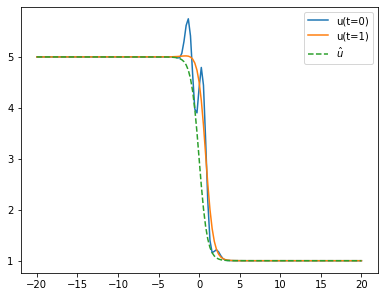

In [14]:
s_, a_ = (u_neg + u_pos)/2, (u_neg - u_pos)/2
plt.plot(x, U[0], label="u(t=0)")
plt.plot(x, U[-1], label="u(t=1)")
plt.plot(x, s_ - a_*np.tanh(a_*x/2), "--", label=r"$\hat{u}$")
plt.legend()
plt.show()